# Two-harmonic Tien–Gordon SIS quasiparticle diode

This notebook calculates the current–voltage (**I–V**) characteristic of a
superconductor–insulator–superconductor (SIS) junction under a two-harmonic AC
drive. It then evaluates the quasiparticle diode efficiency for **positive** DC
voltages:

$$
\eta_{\mathrm{QP}}(V)=\frac{I(V)-|I(-V)|}{I(V)+|I(-V)|}, \qquad V>0.
$$

There are **two independent result sections**:

1. **Before Gaussian smoothing:** calculated current and efficiency as returned by the Tien–Gordon model.
2. **After Gaussian smoothing:** a Gaussian-filtered current, with efficiency **recomputed** from that current (rather than smoothing efficiency directly).


| Calculation | Current data | Efficiency data | Figure |
| --- | --- | --- | --- |
| Before smoothing | `theory_current_raw.dat` | `theory_efficiency_raw.dat` | `theory_iv_eta_raw.png` |
| After smoothing | `theory_current_smoothed.dat` | `theory_efficiency_smoothed.dat` | `theory_iv_eta_smoothed.png` |

All output files are written to the **current working directory**.
The `.dat` files have two columns with commented headers:
voltage in **mV** and either current in **nA** or dimensionless efficiency.


## 1. Model parameters and numerical settings

The values below reproduce the preceding minimal notebook.
Change the physical parameters here; no modification of the functions should be necessary.

**Units:** energies in meV, voltages in mV, temperature in K, resistance in Ω,
and frequency in GHz. The current is calculated internally in amperes and
converted to nanoamperes only when plotted or exported.

The applied drive is

$$V_\mathrm{ac}(t)=V_1\cos(2\pi ft)+V_2\cos(4\pi ft+\phi).$$

The second term oscillates at **twice** the fundamental frequency.
The relative phase $\phi$ controls the symmetry breaking of the driven response.


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.special import expit, jv
from scipy.ndimage import gaussian_filter1d

# --- Junction parameters ---
# Gap (Δ) and Dynes broadening (Γ) are in meV.
# Each electrode has its own values; they happen to be equal here.
GAP_MEV = 0.14
DELTA_1_MEV = DELTA_2_MEV = GAP_MEV
GAMMA_1_MEV = GAMMA_2_MEV = GAP_MEV / 3000
TEMPERATURE_1_K = TEMPERATURE_2_K = 0.2  # Electrode temperatures (K)
R_NORMAL_OHM = 155.0                       # Normal-state junction resistance (Ω)

# --- Two-harmonic drive ---
# V1 is the fundamental amplitude; V2 is the second-harmonic amplitude.
FREQUENCY_GHZ = 1.405
AC_AMPLITUDE_1_MV = 4 * GAP_MEV / 3 * 0.92
AC_AMPLITUDE_2_MV = 2 * GAP_MEV / 3 * 0.92
RELATIVE_PHASE_RAD = 0.0  # Phase of the second harmonic relative to the first

# --- Numerical grids and smoothing ---
MAX_VOLTAGE_MV = 0.5        # Final plotted/exported bias range: [-MAX, +MAX]
N_VOLTAGE = 1201            # Odd count gives a symmetric grid containing V = 0
ENERGY_CUTOFF_MEV = 20.0   # Integrate over [-cutoff, +cutoff]
N_ENERGY = 40001            # Integration grid points (larger = slower, generally more precise)

# Gaussian convolution acts along the voltage axis, in mV.
# Set to 0.0 to make the 'after' output identical to the raw output.
SMOOTHING_SIGMA_MV = 0.003
SMOOTHING_TRUNCATE = 50.0   # Kernel support in units of sigma

# Discard numerically negligible photon sidebands (to speed up summation).
SIDEBAND_WEIGHT_TOLERANCE = 1e-12


## 2. Undriven SIS junction current

For each DC voltage, the model integrates the product of the two Dynes-broadened
superconducting densities of states and the difference of the Fermi occupations.
The integral is evaluated numerically with **Simpson's rule**.

Because an electron gains 1 meV across a 1 mV bias, an energy shift of
`voltage_mV` can be added directly to an array expressed in meV.


In [27]:
# Physical constants in the units used throughout this notebook.
K_B_MEV_PER_K = 8.617333262e-2       # Boltzmann constant, meV/K
HF_OVER_E_MV_PER_GHZ = 0.004135667696  # Photon voltage hf/e for f = 1 GHz, in mV


def dynes_dos(energy_meV, delta_meV, gamma_meV):
    """Normalized superconducting density of states with Dynes broadening.

    Parameters
    ----------
    energy_meV : array
        Quasiparticle energy relative to the chemical potential.
    delta_meV : float
        Superconducting energy gap.
    gamma_meV : float
        Dynes broadening, which regularizes the gap-edge singularity.
    """
    # N(E) = |Re[(E + iΓ) / sqrt((E + iΓ)^2 - Δ^2)]|.
    z = np.asarray(energy_meV) + 1j * max(gamma_meV, 1e-12)
    return np.abs(np.real(z / np.sqrt(z**2 - delta_meV**2)))


def fermi(energy_meV, temperature_K):
    """Fermi–Dirac occupation for energy (meV) and temperature (K)."""
    if temperature_K == 0:
        # Exact zero-temperature step function.
        return (np.asarray(energy_meV) < 0).astype(float)
    # expit(-x) is numerically stable, including for large |x|.
    return expit(-np.asarray(energy_meV) / (K_B_MEV_PER_K * temperature_K))


def sis_current(voltage_mV, energy_meV):
    """Current I_0(V) of the undriven SIS junction, in amperes.

    For each bias, multiply the density of states of electrode 1 at E
    by that of electrode 2 at E + eV, and weight by the difference
    of their thermal occupations.
    """
    dos_1 = dynes_dos(energy_meV, DELTA_1_MEV, GAMMA_1_MEV)
    fermi_1 = fermi(energy_meV, TEMPERATURE_1_K)
    current_A = np.empty_like(voltage_mV, dtype=float)

    for k, voltage in enumerate(voltage_mV):
        shifted_energy = energy_meV + voltage  # eV in meV = V in mV
        integrand = (dos_1
                     * dynes_dos(shifted_energy, DELTA_2_MEV, GAMMA_2_MEV)
                     * (fermi_1 - fermi(shifted_energy, TEMPERATURE_2_K)))
        # Integral gives meV; 1e-3 converts meV to volts in the 1/R prefactor.
        current_A[k] = 1e-3 * simpson(integrand, x=energy_meV) / R_NORMAL_OHM

    return current_A


## 3. Two-harmonic Tien–Gordon current and output helpers

The AC drive creates photon-assisted channels indexed by an integer $n$.
Each channel samples the *undriven* current at a shifted voltage:

$$I(V)=\sum_n |c_n|^2\,I_0\!\left(V+n\frac{hf}{e}\right),$$

where $c_n$ combines Bessel functions of the two drive harmonics.
The code automatically chooses finite sideband cutoffs and verifies that
the retained sideband probabilities sum to approximately one.

The remaining helper functions calculate $\eta_{\mathrm{QP}}$ from a given I–V
curve and produce the plot and `.dat` exports. These helpers are shared by
both result sections, ensuring identical conventions for both outputs.


In [30]:
def driven_current(voltage_mV, base_voltage_mV, base_current_A):
    """Return the two-harmonic Tien–Gordon current I(V), in amperes.

    base_voltage_mV and base_current_A are samples of the *undriven*
    current I_0(V). Tien–Gordon shifts that current by n*h*f/e and
    averages the shifted contributions with weights |c_n|^2.
    """
    photon_voltage_mV = HF_OVER_E_MV_PER_GHZ * FREQUENCY_GHZ  # hf/e

    # Dimensionless drive strengths. The second harmonic has energy 2hf.
    alpha_1 = AC_AMPLITUDE_1_MV / photon_voltage_mV
    alpha_2 = AC_AMPLITUDE_2_MV / (2 * photon_voltage_mV)

    # Finite Bessel-function sums approximate the formally infinite
    # sideband expansion. These adaptive cutoffs match the original model.
    m_max = max(10, int(np.ceil(abs(alpha_2) + 10 * np.sqrt(abs(alpha_2) + 1))))
    effective = abs(alpha_1) + 2 * abs(alpha_2)
    n_max = max(12, int(np.ceil(effective + 10 * np.sqrt(effective + 1))))
    m = np.arange(-m_max, m_max + 1)
    n = np.arange(-n_max, n_max + 1)

    # c_n = sum_m J_(n-2m)(alpha_1) J_m(alpha_2) exp(-i m phi).
    # Each |c_n|^2 is the probability weight of the nth sideband.
    c_n = np.sum(jv(n[:, None] - 2 * m[None, :], alpha_1)
                 * jv(m, alpha_2)[None, :]
                 * np.exp(-1j * m * RELATIVE_PHASE_RAD)[None, :], axis=1)
    weights = np.abs(c_n)**2

    # This check catches a Bessel cutoff that is too small.
    if abs(weights.sum() - 1) > 1e-8:
        raise RuntimeError("Insufficient Tien–Gordon sideband cutoff")
    keep = weights >= SIDEBAND_WEIGHT_TOLERANCE
    n, weights = n[keep], weights[keep]

    # Interpolate I_0(V) at every shifted photon-assisted voltage.
    shifted_voltage = voltage_mV[None, :] + n[:, None] * photon_voltage_mV
    samples = np.interp(shifted_voltage, base_voltage_mV, base_current_A)

    # Outside the precomputed I_0 grid, continue using the normal-state
    # slope dI/dV = 1/R_N, expressed in A/mV. This is the original
    # approximation; it avoids artificially flattening edge samples.
    slope = 1e-3 / R_NORMAL_OHM
    samples = np.where(shifted_voltage < base_voltage_mV[0],
                       base_current_A[0] + slope * (shifted_voltage - base_voltage_mV[0]),
                       samples)
    samples = np.where(shifted_voltage > base_voltage_mV[-1],
                       base_current_A[-1] + slope * (shifted_voltage - base_voltage_mV[-1]),
                       samples)

    print(f"Retained sideband probability: {weights.sum():.12f}")
    return weights @ samples  # Sum_n |c_n|^2 * I_0(V + nhf/e)


def diode_efficiency(voltage_mV, current_A):
    """Calculate eta_QP(V) for positive voltages from the supplied I–V data."""
    positive = voltage_mV > 0  # Exclude V = 0 from the efficiency plot.
    voltage_pos_mV = voltage_mV[positive]
    current_pos_A = current_A[positive]

    # On our symmetric, ascending voltage grid, reversing the array
    # aligns I(-V) with I(+V) without an extra interpolation.
    current_neg_A = current_A[::-1][positive]
    denominator = current_pos_A + np.abs(current_neg_A)

    # Keep undefined/near-zero denominators as NaN rather than divide by zero.
    eta = np.divide(
        current_pos_A - np.abs(current_neg_A), denominator,
        out=np.full_like(current_pos_A, np.nan),
        where=np.abs(denominator) > 1e-15,
    )
    return voltage_pos_mV, eta


def plot_and_export(voltage_mV, current_A, label, stem):
    """Plot I–V and eta_QP and save both numerical arrays and a PNG figure.

    Parameters
    ----------
    voltage_mV, current_A : arrays
        A symmetric voltage grid and its calculated current (in amperes).
    label : str
        Text used in the figure titles and legends.
    stem : str
        Output suffix: 'raw' or 'smoothed'.
    """
    eta_voltage_mV, eta_qp = diode_efficiency(voltage_mV, current_A)
    current_file = f"theory_current_{stem}.dat"
    efficiency_file = f"theory_efficiency_{stem}.dat"
    figure_file = f"theory_iv_eta_{stem}.png"

    # Save 2-column text files for easy use in other plotting software.
    # Current is stored in nA, even though the model uses A internally.
    np.savetxt(current_file, np.column_stack((voltage_mV, 1e9 * current_A)),
               header="Voltage_mV Current_nA")
    np.savetxt(efficiency_file, np.column_stack((eta_voltage_mV, eta_qp)),
               header="Voltage_mV eta_QP")

    # Two panels: whole I–V curve, then the efficiency for V > 0.
    fig, (ax_iv, ax_eta) = plt.subplots(2, 1, figsize=(7, 8))
    ax_iv.plot(voltage_mV, 1e9 * current_A, label=label)
    ax_iv.axhline(0, color="0.6", lw=0.8)
    ax_iv.set(xlabel="DC voltage (mV)", ylabel="Current (nA)",
              title=f"Theoretical I–V — {label}")
    ax_iv.grid(alpha=0.3)
    ax_iv.legend()

    ax_eta.plot(eta_voltage_mV, eta_qp, label=label)
    ax_eta.axhline(0, color="0.6", lw=0.8)
    ax_eta.set(xlabel="DC voltage (mV)", ylabel=r"$\eta_{\mathrm{QP}}$",
               title=f"Theoretical diode efficiency — {label}",
               ylim=(-1.05, 1.05))
    ax_eta.grid(alpha=0.3)
    ax_eta.legend()
    fig.tight_layout()
    fig.savefig(figure_file, dpi=300)
    plt.show()
    print(f"Saved {current_file}, {efficiency_file}, {figure_file}")


## 4. Compute the current (once for both outputs)

We first calculate the undriven SIS current $I_0(V)$, then use the
Tien–Gordon sideband weights to obtain the **unsmoothed** driven current.

The voltage grid is extended slightly beyond the final plotting range.
This **padding** ensures that Gaussian convolution in Section 6 uses genuine
calculated values near the displayed edges, rather than boundary artefacts.
The costly energy integration and photon-assisted sum run **only once**.


In [33]:
# Voltage points that will appear in both exported I–V curves.
voltage_mV = np.linspace(-MAX_VOLTAGE_MV, MAX_VOLTAGE_MV, N_VOLTAGE)
voltage_step_mV = voltage_mV[1] - voltage_mV[0]

# The Gaussian kernel extends about TRUNCATE * sigma on each side.
# The same extra points are computed for the raw curve before smoothing.
padding_points = int(np.ceil(SMOOTHING_TRUNCATE * SMOOTHING_SIGMA_MV
                                 / voltage_step_mV))
voltage_full_mV = voltage_mV[0] + voltage_step_mV * np.arange(
    -padding_points, N_VOLTAGE + padding_points)
full_max_mV = np.max(np.abs(voltage_full_mV))

# Photon-assisted contributions need I_0 at shifted voltages. Calculate
# I_0 on a somewhat wider grid so most shifted samples can be interpolated.
voltage_margin_mV = abs(AC_AMPLITUDE_1_MV) + abs(AC_AMPLITUDE_2_MV) + 0.5
base_voltage_mV = np.linspace(-full_max_mV - voltage_margin_mV,
                               full_max_mV + voltage_margin_mV, N_VOLTAGE)
energy_meV = np.linspace(-ENERGY_CUTOFF_MEV, ENERGY_CUTOFF_MEV, N_ENERGY)

base_current_A = sis_current(base_voltage_mV, energy_meV)
raw_current_full_A = driven_current(voltage_full_mV, base_voltage_mV, base_current_A)

# Remove padding for the raw figure and .dat files.
raw_current_A = raw_current_full_A[padding_points:padding_points + N_VOLTAGE]


Retained sideband probability: 0.999999999999


## 5. Before Gaussian smoothing — theoretical I–V and efficiency

This section uses the **direct model output**, without further broadening.
It displays both theoretical plots and saves their numerical data.


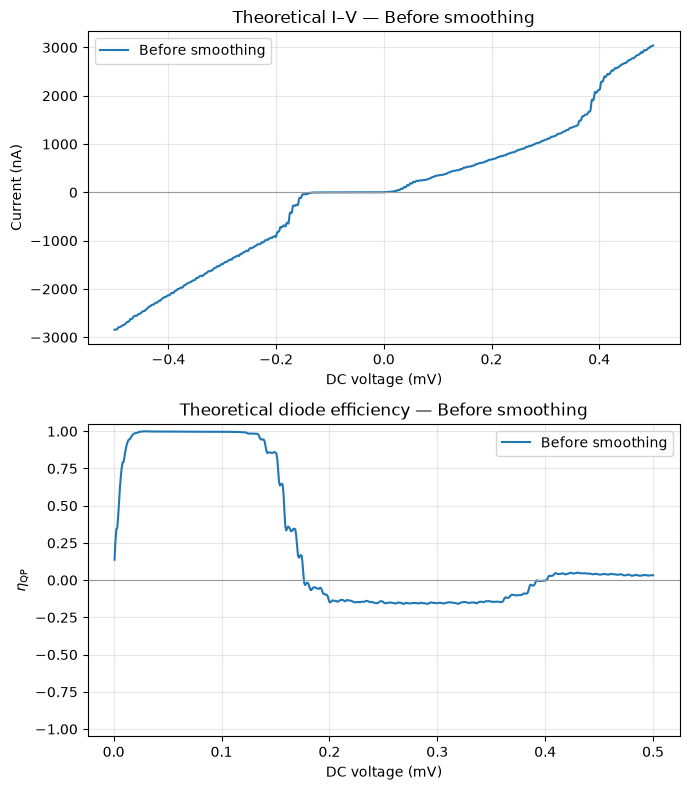

Saved theory_current_raw.dat, theory_efficiency_raw.dat, theory_iv_eta_raw.png


In [36]:
# First output: theoretical current with NO Gaussian convolution.
plot_and_export(voltage_mV, raw_current_A, label="Before smoothing", stem="raw")

## 6. After Gaussian smoothing — theoretical I–V and efficiency

The voltage-dependent **current**, not the efficiency, is convolved with a
Gaussian of standard deviation `SMOOTHING_SIGMA_MV`.
The filter expects a width in **grid points**, so the code divides the width in
mV by the voltage spacing in mV.

Once smoothed, the diode efficiency is computed again from $I_{\rm smooth}(V)$
and $I_{\rm smooth}(-V)$. This keeps the two sections physically consistent.
Set `SMOOTHING_SIGMA_MV = 0.0` to turn smoothing off completely.


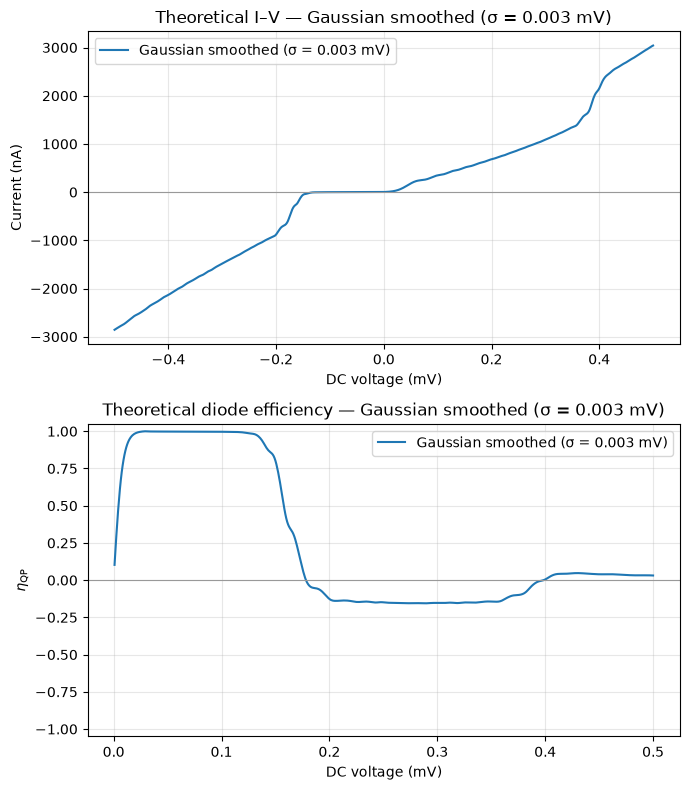

Saved theory_current_smoothed.dat, theory_efficiency_smoothed.dat, theory_iv_eta_smoothed.png


In [39]:
if SMOOTHING_SIGMA_MV > 0:
    # Width in sample points = physical Gaussian width / voltage step.
    # Smooth the PADDED curve to avoid edge effects in the displayed range.
    smoothed_current_full_A = gaussian_filter1d(
        raw_current_full_A,
        sigma=SMOOTHING_SIGMA_MV / voltage_step_mV,
        truncate=SMOOTHING_TRUNCATE,
        mode="nearest",
    )
else:
    # Zero broadening: preserve the raw result exactly.
    smoothed_current_full_A = raw_current_full_A.copy()

# Trim the same padding used for the unsmoothed result.
smoothed_current_A = smoothed_current_full_A[
    padding_points:padding_points + N_VOLTAGE]

# Efficiency is recalculated inside plot_and_export from the smoothed current.
plot_and_export(voltage_mV, smoothed_current_A,
                label=f"Gaussian smoothed (σ = {SMOOTHING_SIGMA_MV:g} mV)",
                stem="smoothed")
